# Greek study and NASA regional comparison

Executed development-data audit; no temporal model trained. The Greek method is the reference for the next experiment design. See [the full review](../docs/greek-study-focus.md). These selected areas and three weather years do not establish national climate equivalence or forecast transfer skill.

In [1]:
from pathlib import Path
import os, sys
import pandas as pd
from IPython.display import display, Image
root = next(p for p in [Path.cwd(), Path.cwd().parent, Path.cwd() / "forecasting"] if (p / "src/firecast").is_dir())
os.environ.setdefault("MPLCONFIGDIR", "/tmp/firecast-mpl")
os.environ.setdefault("XDG_CACHE_HOME", "/tmp/firecast-cache")
sys.path.insert(0, str(root / "src"))
from firecast.regional_similarity import run
report = run(root / "configs/greek-study-focus.json", root, root / "docs/greek-lebanon-similarity.json")

{
  "profiles": {
    "greece": {
      "eligible_cells": 326,
      "used_weather_points": 16,
      "development_point_days": 17536,
      "annual_temperature_c": 16.34385114862747,
      "annual_rain_mm": 723.8378118609407,
      "summer_rain_mm": 105.83414110429449,
      "winter_rain_mm": 283.94298568507156,
      "summer_temperature_c": 25.24892164903871,
      "winter_temperature_c": 7.820409780167121,
      "elevation_m_mean": 463.11641741434414,
      "slope_deg_mean": 13.711764919517483,
      "vegetation_fraction_mean": 0.8243684286627971,
      "elevation_m_std": 355.0953558093611,
      "slope_deg_std": 4.952081001131126,
      "vegetation_fraction_std": 0.2752975212451211
    },
    "southern_turkey": {
      "eligible_cells": 333,
      "used_weather_points": 16,
      "development_point_days": 17536,
      "annual_temperature_c": 13.564749183490058,
      "annual_rain_mm": 655.4994494494495,
      "summer_rain_mm": 67.5488888888889,
      "winter_rain_mm": 361.644654654

,eligible_cells,used_weather_points,summer_temperature_c,summer_rain_mm,winter_rain_mm,elevation_m_mean
greece,326.0,16.0,25.248922,105.834141,283.942986,463.116417
southern_turkey,333.0,16.0,23.094014,67.548889,361.644655,1017.375356
portugal,393.0,16.0,22.948883,33.181654,185.476845,207.376717
morocco,400.0,16.0,24.719926,19.340417,169.040417,1043.548269
lebanon,124.0,9.0,24.376602,8.460296,310.336344,945.461142


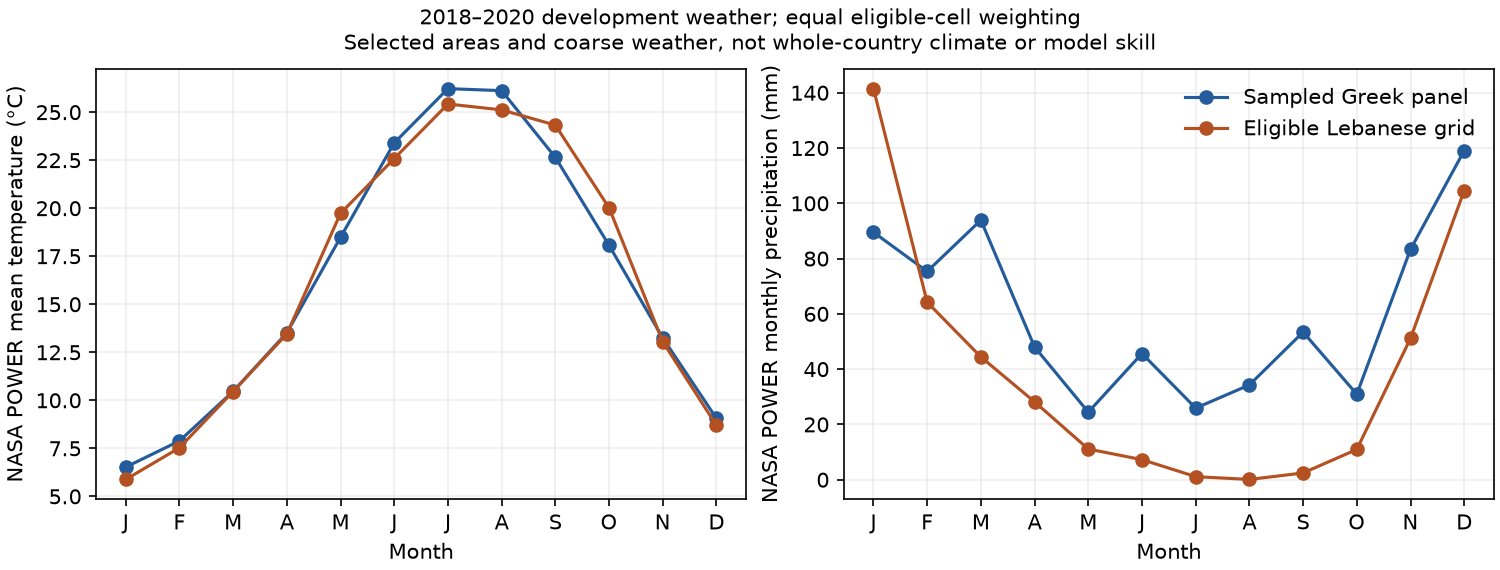

In [2]:
summaries = pd.DataFrame({name: item["summary"] for name, item in report["profiles"].items()}).T
display(summaries[["eligible_cells", "used_weather_points", "summer_temperature_c", "summer_rain_mm", "winter_rain_mm", "elevation_m_mean"]])
display(Image(filename=str(root / "docs/figures/greek-lebanon-seasonality.png")))

The Greek panel and Lebanon have similar seasonal temperatures, but measured summer precipitation and terrain differ substantially. Comparison uses only 2018–2020 weather and cached static observations, equal eligible-cell weights and nearest actual weather points. No fire label or test metric is consulted. Coarse weather, selected geography and old/reprocessed land cover limit this comparison.

In [3]:
display(pd.DataFrame(report["distances"])[["region", "standardized_distance"]])
assert report["fire_labels_or_test_metrics_read"] is False
assert report["period"] == ["2018-01-01", "2021-01-01"]

,region,standardized_distance
0,morocco,1.274080
1,southern_turkey,1.294965
2,greece,1.460075
3,portugal,1.994628


## Next design and source differences

Prioritize ten-day LSTM against the same-feature tree controls. Add NASA NDVI/LST/soil-moisture histories only after QA and availability checks. Keep satellite-detected occurrence, representative negatives and existing southern-conflict/cloud exclusions. The paper instead uses large-fire danger and sampled negatives; its supplement assumes forecasts from shifted historical weather. The pinned implementation and paper state different dense-layer widths. The old Greek geographic holdout cannot become a training region while retaining its independent-test claim. A new confirmation period must be registered before development; this notebook does not train, choose thresholds or reopen test outcomes.